# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Бойко Роман'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 4       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Бойко Роман | ШІ-32 | номер 4


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 4   ·   Бойко Роман   ·   ШІ-32

   Ринок:  Kherson
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import numpy as np
import pandas as pd

FILE = "ціни_україна_2014_2017.csv"
df = pd.read_csv(FILE)
my_data = df[(df["ринок"] == MARKET) & (df["товар"] == GOOD)]


my_data = my_data.copy()
my_data['date'] = pd.to_datetime(dict(year=my_data['рік'], month=my_data['місяць'], day=1))
my_data = my_data.set_index("date")

prices = my_data["ціна"]

full_grid = pd.date_range(start='2014-03-01', end='2017-12-01', freq='MS')
prices = prices.reindex(full_grid)

print()
print("Total months in grid:", len(prices))
print("Months with values:", prices.notna().sum())
print("Missing months:\n", prices[prices.isna()])
print(my_data)



Total months in grid: 46
Months with values: 45
Missing months:
 2017-08-01   NaN
Freq: MS, Name: ціна, dtype: float64
              ринок                товар одиниця валюта   рік  місяць     ціна
date                                                                          
2014-03-01  Kherson  Sour cream - Retail       L    UAH  2014       3  21.6667
2014-04-01  Kherson  Sour cream - Retail       L    UAH  2014       4  21.2533
2014-05-01  Kherson  Sour cream - Retail       L    UAH  2014       5  21.7300
2014-06-01  Kherson  Sour cream - Retail       L    UAH  2014       6  21.8600
2014-07-01  Kherson  Sour cream - Retail       L    UAH  2014       7  21.8000
2014-08-01  Kherson  Sour cream - Retail       L    UAH  2014       8  21.8000
2014-09-01  Kherson  Sour cream - Retail       L    UAH  2014       9  21.9833
2014-10-01  Kherson  Sour cream - Retail       L    UAH  2014      10  21.7867
2014-11-01  Kherson  Sour cream - Retail       L    UAH  2014      11  21.9433
2014-12-01 

**Висновок до завдання 1:**

1. скільки місяців у сітці та скільки з них мають вимір: всього 46 місяців і 45 з них мають вимір
2. у якому саме місяці пропуск: серпень 2017
3. **чому** цей пропуск виник — і чи він у вашому ряді один: пропуск лише один. він є системним і наявним в усіх рядах цього набору даних через відсутність статистики за цей період

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
prices_interpolate = prices.interpolate()

prices_ffill = prices.ffill()

prices_bfill = prices.bfill()

print("Інтерполяція:", prices_interpolate.loc['2017-08-01'])
print("Ffill:", prices_ffill.loc['2017-08-01'])
print("Bfill:", prices_bfill.loc['2017-08-01'])

prices = prices.interpolate()
print(prices)

Інтерполяція: 44.37335
Ffill: 44.54
Bfill: 44.2067
2014-03-01    21.66670
2014-04-01    21.25330
2014-05-01    21.73000
2014-06-01    21.86000
2014-07-01    21.80000
2014-08-01    21.80000
2014-09-01    21.98330
2014-10-01    21.78670
2014-11-01    21.94330
2014-12-01    21.97670
2015-01-01    22.12000
2015-02-01    22.38670
2015-03-01    24.08000
2015-04-01    24.70000
2015-05-01    26.11670
2015-06-01    26.38330
2015-07-01    26.72330
2015-08-01    26.63000
2015-09-01    27.28670
2015-10-01    27.53000
2015-11-01    28.63000
2015-12-01    29.52330
2016-01-01    29.82000
2016-02-01    31.69330
2016-03-01    32.28330
2016-04-01    32.48670
2016-05-01    32.75000
2016-06-01    31.39000
2016-07-01    32.15670
2016-08-01    32.57000
2016-09-01    32.42000
2016-10-01    33.54000
2016-11-01    34.85000
2016-12-01    37.79330
2017-01-01    38.67670
2017-02-01    40.25670
2017-03-01    42.89670
2017-04-01    43.80670
2017-05-01    43.86330
2017-06-01    43.93670
2017-07-01    44.54000
2017-0

**Висновок до завдання 2:**
1. значення, яке дає кожен спосіб;
Перенесення попереднього значення (Forward Fill): 44.54 грн.
Перенесення наступного значення (Backward Fill): 44.21 грн.
Лінійна інтерполяція (Linear Interpolate): 44.37 грн.

2. Обраний спосіб та обґрунтування:
Я обираю лінійну інтерполяцію. Оскільки пропущено лише один місяць, а ціна між липнем і вереснем змінилася несуттєво, тому логічно, що в серпні був плавний перехід. Перенесення значень створює штучну нульову зміну за один з місяців, що може викривити подальший аналіз, тоді як інтерполяція зберігає природний тренд.

3. Умова, за якої заповнювати пропуск неприпустимо:
Заповнювати пропуски категорично неприпустимо, коли дані зникають систематично на тривалий час або назавжди.

Приклад із набору даних: У цьому датасеті у 2014 році назавжди зникають ринки АР Крим та м. Севастополь. Якби ми спробували заповнити їхні пропуски до 2017 року, ми б штучно згенерували 3 роки незмінних цін, яких насправді не існує.


## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

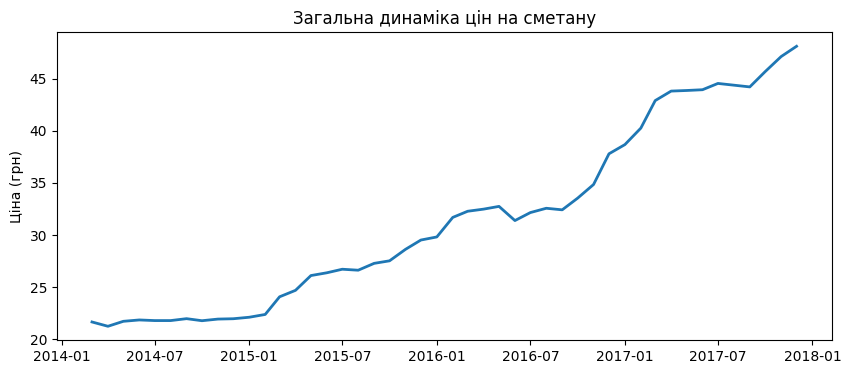

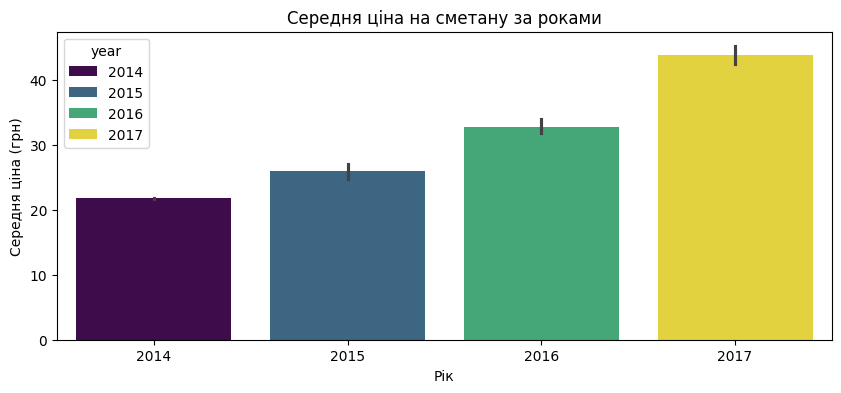

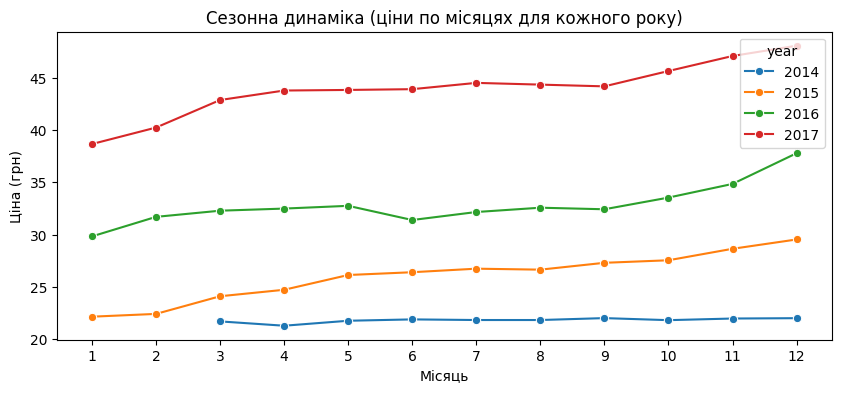

In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt
import seaborn as sns

df_viz = prices.reset_index()
df_viz.columns = ["date", "price"]
df_viz['year'] = df_viz['date'].dt.year
df_viz['month'] = df_viz['date'].dt.month

plt.figure(figsize=(10, 4))
plt.plot(df_viz["date"], df_viz["price"], lw=2)
plt.title('Загальна динаміка цін на сметану')
plt.ylabel('Ціна (грн)')
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(x='year', y='price', data=df_viz, hue='year', palette="viridis")
plt.title('Середня ціна на сметану за роками')
plt.xlabel('Рік')
plt.ylabel('Середня ціна (грн)')
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(x='month', y='price', hue='year', data=df_viz, palette='tab10', marker='o')
plt.title('Сезонна динаміка (ціни по місяцях для кожного року)')
plt.xlabel('Місяць')
plt.ylabel('Ціна (грн)')
plt.xticks(range(1, 13))
plt.show()

**Висновок до завдання 3:**
1. Лінійний графік загальної динаміки.
Питання: Який загальний напрямок руху та характер зміни цін на сметану протягом усього періоду?

Обґрунтування геометрії та шкали: Геометрія з'єднаних ліній обрана, оскільки вона підкреслює безперервність і послідовність часового ряду. Вона відображає абсолютні зміни ціни в часі.

2. Стовпчаста діаграма середньорічної ціни.

Питання: Як змінювалася середня вартість сметани з року в рік?

Обґрунтування геометрії та шкали: Геометрія стовпців обрана тому, що вона найкраще підходить для порівняння середніх значень між роками. Лінійна шкала та висота стовпців від нуля чітко ілюструють абсолютну величину та масштаб зростання ціни.

3. Сезонний лінійний графік.

Питання: Чи існує повторювання коливання цін залежно від місяця?

Обґрунтування геометрії та шкали: Накладення кількох ліній на спільній осі місяців дозволяє візуально порівняти форму сезонних коливань та побачити, чи збігаються піки й падіння в одні й ті ж місяці щороку.

4. Неочікувана знахідка: До побудови графіків можна було очікувати плавного та помірного зростання цін. Проте графіки показали дуже різкий, стрімкий стрибок вартості сметани майже вдвічі при переході від 2014 до 2015 року, а також значне збільшення самої амплітуди коливань ціни всередині року.
*(напишіть тут)*

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [6]:
!pip install statsmodels


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: C:\Users\romandzo95\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


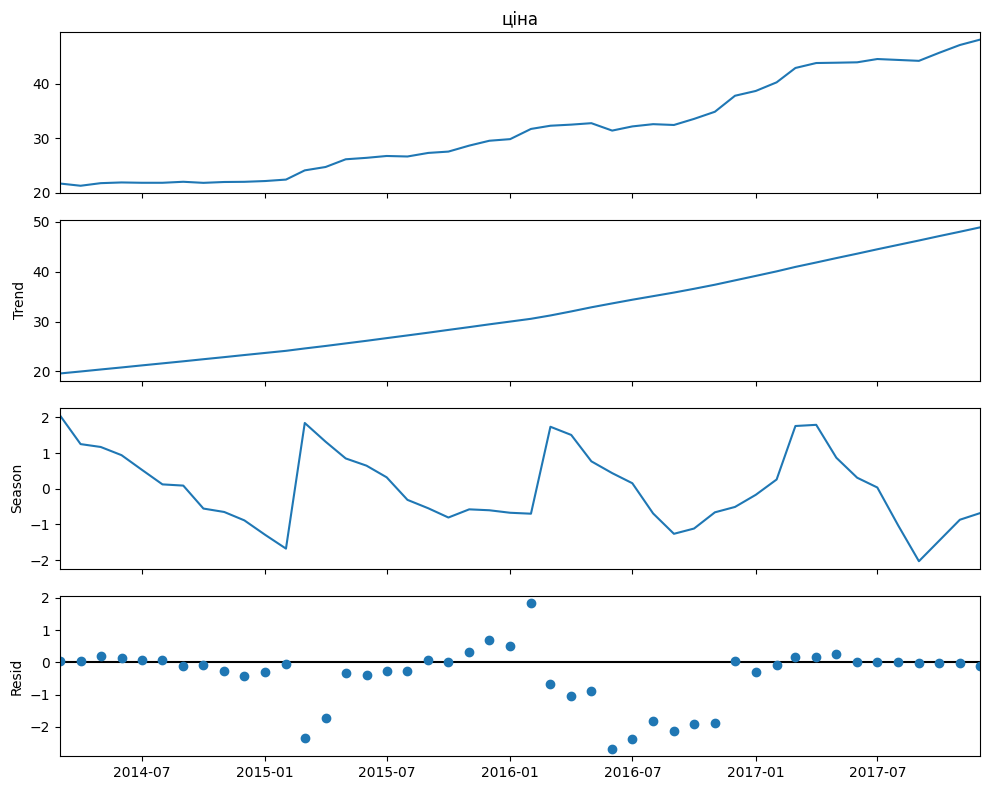

F_S: 0.5251
F_T: 0.9895


In [7]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(prices, period=12, robust=True)
result=stl.fit()

trend = result.trend
seasonal = result.seasonal
residual = result.resid

fig = result.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

var_resid = np.var(residual)
F_s = max(0, 1-var_resid/np.var(seasonal+residual))
F_t = max(0, 1-var_resid/np.var(trend+residual))
print(f"F_S: {F_s:.4f}")
print(f"F_T: {F_t:.4f}")

**Висновок до завдання 4:**
1. Чотирипанельний графік розкладання побудовано. На графіку видно потужний висхідний тренд та сезонні коливання, амплітуда яких із часом зростає.
2. Числові значення сили становлять: сила сезонності $F_S$ = 0.5251, сила тренду $F_T$ = 0.9895.
3. Висновок щодо сезонності: значенням для підтвердження наявності сезонності вважається $F_S \ge 0.6$. Оскільки для мого ряду $F_S \approx 0.53$, можна зробити висновок, що сильна сезонність у цьому ряді відсутня. Спостерігаються певні сезонні коливання, але вони є занадто слабкими, щоб вважати ряд повністю сезонним.
*(напишіть тут)*

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

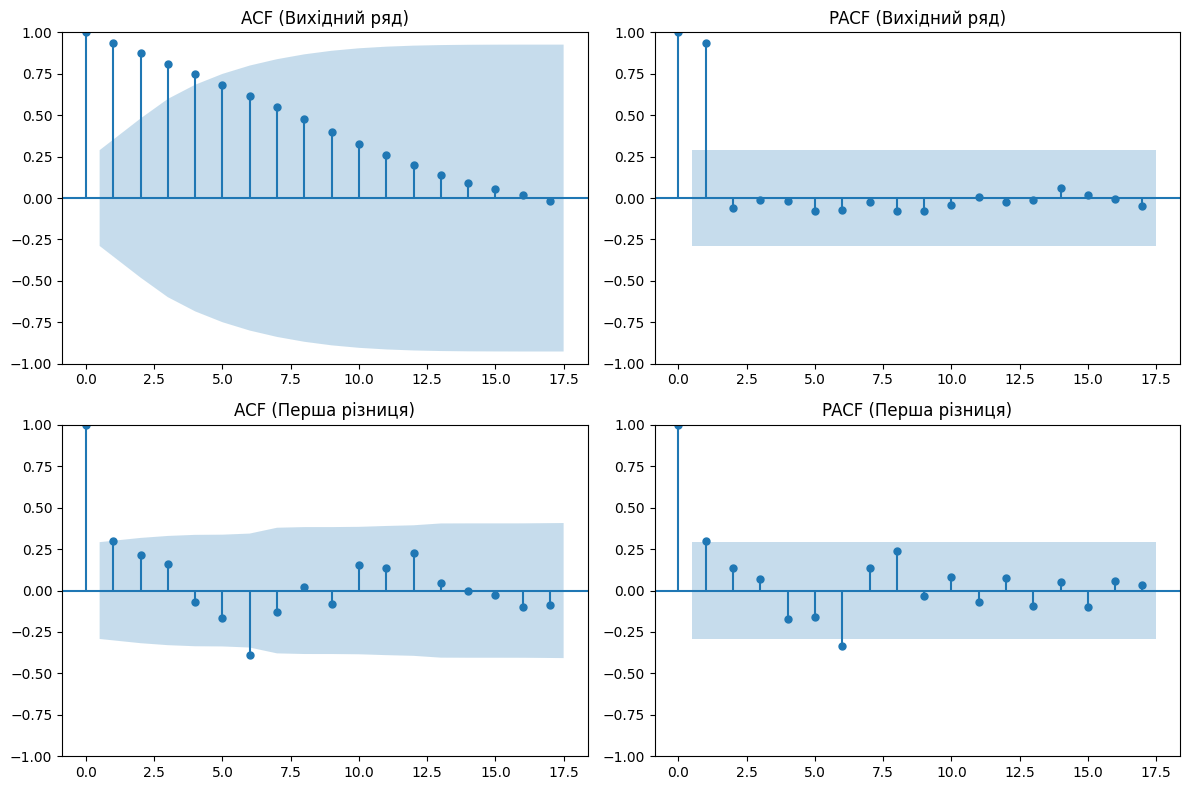

          Ряд  ADF p-value  KPSS p-value
     Вихідний     0.999071          0.01
Перша різниця     0.001525          0.10


In [8]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')
y = prices
y_diff = prices.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_acf(y, ax=axes[0, 0], title='ACF (Вихідний ряд)')
plot_pacf(y, ax=axes[0, 1], title='PACF (Вихідний ряд)')
plot_acf(y_diff, ax=axes[1, 0], title='ACF (Перша різниця)')
plot_pacf(y_diff, ax=axes[1, 1], title='PACF (Перша різниця)')
plt.tight_layout()
plt.show()

adf_orig = adfuller(y, autolag='AIC')[1]
kpss_orig = kpss(y, regression='c', nlags='auto')[1]

adf_diff = adfuller(y_diff, autolag='AIC')[1]
kpss_diff = kpss(y_diff, regression='c', nlags='auto')[1]

df_tests = pd.DataFrame({
    'Ряд': ['Вихідний', 'Перша різниця'],
    'ADF p-value': [adf_orig, adf_diff],
    'KPSS p-value': [kpss_orig, kpss_diff]
})
print(df_tests.to_string(index=False))

**Висновок до завдання 5:**
1. Графіки ACF і PACF: На графіку ACF вихідного ряду значення автокореляції спадають дуже повільно, що є класичною ознакою ряду з сильним трендом. Після взяття першої різниці графіки ACF та PACF різко "обрізаються", і більшість значень потрапляють у інтервал, що вказує на перехід до стаціонарного стану.
2. Таблиця з p-значеннями: Виведена за допомогою коду (ADF вихідного $\approx$ 0.999, KPSS $\approx$ 0.010; ADF різниці $\approx$ 0.0015, KPSS $\approx$ 0.100).
3. Висновок про стаціонарність та узгодженість тестів:Вихідний ряд: Тест ADF має p-value > 0.05. Тест KPSS має p-value < 0.05. Тести повністю узгоджуються між собою — вихідний ряд є нестаціонарним.Перша різниця: Тест ADF має p-value < 0.05. Тест KPSS має p-value > 0.05. Обидва тести знову узгоджуються — перша різниця ряду є стаціонарною.
4. Пояснення розбіжностей: Оскільки обидва тести узгоджуються як для вихідного ряду, так і для його першої різниці, додаткових пояснень не потрібно.
*(напишіть тут)*

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [9]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
from sklearn.metrics import mean_absolute_error, mean_squared_error
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100
y=prices.values
n=len(y)
n_folds = 7
step=3
init_train = n - n_folds*step
results = {
    'Naive': {'MAE': [], 'RMSE': [], 'MAPE': []},
    'Seasonal naive': {'MAE': [], 'RMSE': [], 'MAPE': []},
    'Mean pred': {'MAE': [], 'RMSE': [], 'MAPE': []},
    'Drift pred': {'MAE': [], 'RMSE': [], 'MAPE': []}
}
for i in range(n_folds):
    train = y[:init_train + i*step] 
    test = y[(init_train + i*step) : (init_train+(i+1)*step)]

    naive = np.repeat(train[-1], step)
    snaive = train[-12:-12+step]
    mean_pred = np.repeat(np.mean(train), step)

    slope = (train[-1] - train[0]) / (len(train)-1)
    drift_pred = train[-1] + slope*np.arange(1, step+1)

    preds = {'Naive': naive, 'Seasonal naive': snaive, 'Mean pred': mean_pred, 'Drift pred': drift_pred}

    for name, pred in preds.items():
        results[name]['MAE'].append(mean_absolute_error(test, pred))
        results[name]['RMSE'].append(np.sqrt(mean_squared_error(test, pred)))
        results[name]['MAPE'].append(mape(test, pred))

results_cv = pd.DataFrame({
    name: {metric: np.mean(vals) for metric, vals in m.items()}
    for name, m in results.items()
}).T

print("==== Ретроспективна перевірка (7 фолдів по 3 кроки) ====")
print(results_cv.round(3))
print("\n")

train_75 = y[:int(n*0.75)]
test_25 = y[int(n*0.75):]
drift_slope_75 = (train_75[-1] - train_75[0]) / (len(train_75)-1)
drift_75_pred = train_75[-1] + drift_slope_75 * np.arange(1, len(test_25) + 1)

mae_cv = results_cv.loc['Drift pred', 'MAE']
mae_75 = mean_absolute_error(test_25, drift_75_pred)

print(f"MAE моделі Дрейф (рухомий початок): {mae_cv:.3f}")
print(f"MAE моделі Дрейф (поділ 75/25): {mae_75:.3f}")
print(f"Відмінність у оцінці: помилка відрізняється у {mae_75 / mae_cv:.2f} разів.")

==== Ретроспективна перевірка (7 фолдів по 3 кроки) ====
                   MAE    RMSE    MAPE
Naive            1.639   1.820   4.095
Seasonal naive   9.054   9.095  22.502
Mean pred       11.920  11.969  29.389
Drift pred       1.171   1.405   2.960


MAE моделі Дрейф (рухомий початок): 1.171
MAE моделі Дрейф (поділ 75/25): 2.985
Відмінність у оцінці: помилка відрізняється у 2.55 разів.


**Висновок до завдання 6:**
1. Таблиця метрик: Представлена у виводі коду.

2. Найкращий базис: Найкращим базисом виявився Дрейф, оскільки він має найменші значення MAE, RMSE та MAPE. Це повністю пояснюється властивостями мого ряду: він має дуже сильний висхідний тренд. Дрейф, на відміну від наївного прогнозу чи середнього, екстраполює загальний лінійний нахил, тому найкраще вловлює постійне зростання ціни.

3. Порівняння з поділом 75/25: Оцінка моделі Дрейфу при звичайному випадковому поділі 75/25 показує більшу помилку MAE, ніж при ретроспективній перевірці з рухомим початком. Це доводить, що класичний поділ 75/25 погано працює для рядів, що зростають, адже тестова вибірка припадає лише на найвищі значення кінця 2017 року. Перевірка з рухомим початком дає об'єктивнішу оцінку, бо тестує модель на різних ділянках ряду.
*(напишіть тут)*

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

==== ARIMA(1,1,1) (7 фолдів по 3 кроки) ====
MAE:  1.710
RMSE: 1.911
MAPE: 4.402%



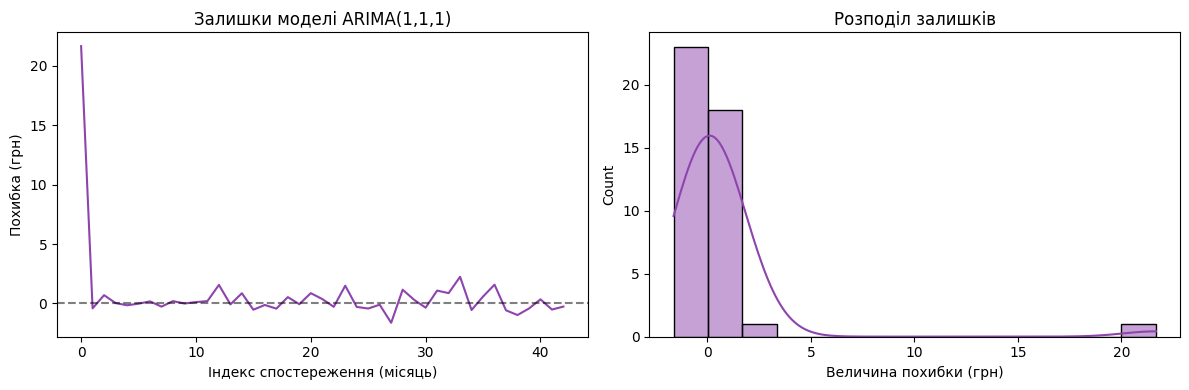

In [10]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA

arima_res = {'MAE': [], 'RMSE': [], 'MAPE': []}

for i in range(n_folds):
    train = y[:init_train + i*step] 
    test = y[(init_train + i*step) : (init_train+(i+1)*step)]

    arima = ARIMA(train, order = (1,1,1))
    arima_fit = arima.fit()
    pred = arima_fit.forecast(steps=step)
    arima_res['MAE'].append(mean_absolute_error(test, pred))
    arima_res['RMSE'].append(np.sqrt(mean_squared_error(test, pred)))
    arima_res['MAPE'].append(mape(test, pred))

print("==== ARIMA(1,1,1) (7 фолдів по 3 кроки) ====")
print(f"MAE:  {np.mean(arima_res['MAE']):.3f}")
print(f"RMSE: {np.mean(arima_res['RMSE']):.3f}")
print(f"MAPE: {np.mean(arima_res['MAPE']):.3f}%\n")


residuals = arima_fit.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(residuals, color='#8E44AD')
axes[0].set_title('Залишки моделі ARIMA(1,1,1)')
axes[0].set_xlabel('Індекс спостереження (місяць)')
axes[0].set_ylabel('Похибка (грн)')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.5)

sns.histplot(residuals, kde=True, ax=axes[1], color='#8E44AD')
axes[1].set_title('Розподіл залишків')
axes[1].set_title('Розподіл залишків')
axes[1].set_xlabel('Величина похибки (грн)')
plt.tight_layout()
plt.show()

**Висновок до завдання 7:**
1. Оцінка моделі ARIMA(1,1,1): одель показала такі метрики: MAE $\approx$ 1.710, RMSE $\approx$ 1.911, MAPE $\approx$ 4.40%.
2. Обґрунтування власного порядку (p, d, q): Спираючись на результати Завдання 5, ряд стає стаціонарним після першого диференціювання, тому $d=1$. На графіках ACF та PACF першої різниці ми бачимо, що значущі кореляції відсутні. Тому я б обрав значно простішу модель — ARIMA(0, 1, 0) з урахуванням дрейфу, або ж ARIMA(1, 1, 0), оскільки складніша модель схильна до перенавчання на такому короткому ряді.
3. Порівняння з найкращим базисом: Найкращий базис із Завдання 6 показав MAE $\approx$ 1.171. Оцінка ARIMA(1,1,1) (MAE $\approx$ 1.710) виявилася гіршою. Це абсолютно закономірний результат: для коротких часових рядів із сильним лінійним трендом проста екстраполяція дрейфу майже завжди перевершує складні моделі, яким бракує даних для стабільної оцінки параметрів. Тому використання складної моделі ARIMA(1,1,1) для цього ряду не виправдане.
4. Аналіз залишків: На побудованих графіках видно, що залишки коливаються навколо нуля і візуально нагадують білий шум, хоча їхній розподіл не є ідеально нормальним.
*(напишіть тут)*

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

==== T scan results ====
Date: 03.2017
t-statistic: 16.068 (p-value: 5.8451e-20)
Mean 'BEFORE':    27.85 грн
Mean 'AFTER': 44.85 грн



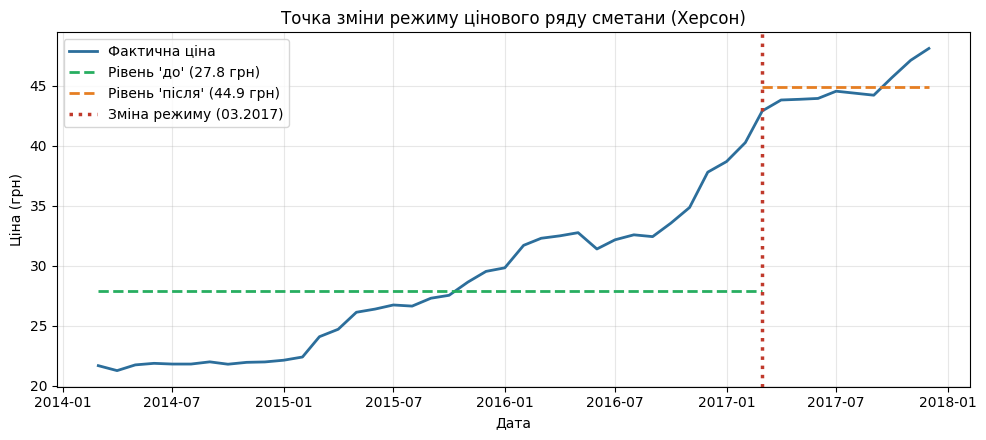

In [11]:
# Завдання 8. Точка зміни режиму
from scipy import stats

all_dates = prices.index
all_prices = prices.values
n = len(all_prices)

results = []
for i in range(3, n-3):
    before = all_prices[:i]
    after = all_prices[i:]
    t_stat, p_value = stats.ttest_ind(after, before, equal_var=False)
    results.append({
        'index': i,
        'date': all_dates[i],
        't_stat': t_stat,
        'p_val': p_value,
        'mean_before': np.mean(before),
        'mean_after': np.mean(after)
    })
df_scan_res = pd.DataFrame(results)

best_split = df_scan_res.loc[df_scan_res["t_stat"].idxmax()]
split_date = best_split["date"]

print("==== T scan results ====")
print(f"Date: {split_date.strftime('%m.%Y')}")
print(f"t-statistic: {best_split['t_stat']:.3f} (p-value: {best_split['p_val']:.4e})")
print(f"Mean 'BEFORE':    {best_split['mean_before']:.2f} грн")
print(f"Mean 'AFTER': {best_split['mean_after']:.2f} грн\n")

plt.figure(figsize=(10, 4.5))
plt.plot(all_dates, all_prices, color='#2C6E9B', lw=2, label='Фактична ціна')

plt.hlines(best_split['mean_before'], xmin=all_dates[0], xmax=split_date, 
           colors='#27AE60', linestyles='--', lw=2, label=f"Рівень 'до' ({best_split['mean_before']:.1f} грн)")
plt.hlines(best_split['mean_after'], xmin=split_date, xmax=all_dates[-1], 
           colors='#E67E22', linestyles='--', lw=2, label=f"Рівень 'після' ({best_split['mean_after']:.1f} грн)")

# Вертикальна лінія точки зламу
plt.axvline(split_date, color='#C0392B', linestyle=':', lw=2.5, 
            label=f"Зміна режиму ({split_date.strftime('%m.%Y')})")

plt.title('Точка зміни режиму цінового ряду сметани (Херсон)')
plt.xlabel('Дата')
plt.ylabel('Ціна (грн)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок до завдання 8:**
1. Графік ряду з точкою зламу: Графік побудовано.
2. Параметри знайденої точки:   Дата зміни режиму: Березень 2017 року.   Значення $t$-статистики: $t \approx 16.068$ ($p$-value $\approx 5.85 \times 10^{-20}$).   Середній рівень «ДО»: 27.85 грн.   Середній рівень «ПІСЛЯ»: 44.85 грн.
3. Знайдена точка є високозначущою ($p < 0.001$). Середній рівень цін після березня 2017 року зріс більш ніж на 17 грн (приріст склав $\approx 61\%$).
4. Відмінність від звичайного сезонного сплеску:Сезонний сплеск — це тимчасове коливання, після якого ціна повертається до попереднього рівня в межах річного циклу.   Знайдена точка є саме зсувом рівня: після стрибка на початку 2017 року ціна більше не повернулася до діапазону 25–33 грн, закріпившись на рівні понад 44 грн за кг, що було викликано економічними чинниками та інфляцією, а не сезонністю.
*(напишіть тут)*

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [12]:
# Завдання 9. Рецензія на чужий аналіз

1. Непомічений пропуск у датах (клітинки 1–2)   Суть помилки: Автор створив календарну сітку на 46 місяців, а з бази підтягнув 45. Банальний isna().sum() видав нуль, бо пропущеного рядка в таблиці просто фізично немає. Через це зроблено поспішний висновок: «пропусків немає, дані ідеальні».   Чим небезпечна: У часовому ряді випав цілий місяць, через що вся хронологія зсунулася. Будь-які лаги ($t-1, t-12$), автокореляція та розрахунки для ARIMA далі рахуються з перекосом.
2. Висновок по двох крайніх точках (клітинка 3)   Суть помилки: Узяли першу ціну на початку 2014-го і останню в кінці 2017-го, поділили одне на одне й видали висновок про «падіння купівельної спроможності в 2.5 раза».   Чим небезпечна: Повний ігнор того, що коїлося всередині періоду: гречка злітала вище 30 грн, а потім суттєво просіла. До того ж номінальна ціна одного товару без урахування інфляції та доходів узагалі нічого не каже про реальну купівельну спроможність людей.
3. Порівняння MAE в лоб для різних масштабів (клітинка 4)   Суть помилки: Порівняли абсолютну похибку наївного прогнозу гречки (1.38 грн) та яловичини (1.51 грн) і заявили, що м'ясо прогнозувати важче, бо цифра більша.   Чим небезпечна: Яловичина коштує під 80–100 грн, а гречка — 15–25 грн. Помилка в півтори гривні на дорогому м'ясі — це мізерні 1.5–2%, тоді як на гречці це відчутні 8–10%. Порівнювати абсолютні гривні замість відносних похибок (наприклад, MAPE) тут некоректно й веде до хибних оцінок.
4. Хибна кореляція і висмоктана причинність (клітинка 5)   Суть помилки: Порахували кореляцію Пірсона ($r = 0.996$) просто за «сирими» цінами двох областей і вирішили, що Львівщина диктує ціни Вінниччині.   Чим небезпечна: Класична хибна кореляція (spurious correlation). Якщо два ряди мають однаковий висхідний тренд (девальвація, інфляція 2014–2015 рр.), математика завжди покаже високий коефіцієнт. Але кореляція ніколи не доводить причинно-наслідковий зв'язок і тим паче його напрямок.
5. Притягнута за вуха сезонність через STL (клітинка 6)   Суть помилки: Запустили розкладання STL із періодом 12 на уривку менше 4 років, де був разовий ціновий шок, і вирішили, що в ряду є чітка сезонність.   Чим небезпечна: STL чисто механічно витягне хвилю, якщо йому жорстко задати period=12. Натягувати кризовий стрибок на сезонність ризиковано: сезонні моделі (SARIMA) почнуть малювати штучні щорічні коливання там, де був просто разовий стрибок ринку.
6. Тест Дікі-Фуллера зрозуміли з точністю до навпаки (клітинка 7)   Суть помилки: Отримали $p\text{-value} = 0.233 > 0.05$, не відхилили нульову гіпотезу і написали: «ряд стаціонарний, диференціювати не треба».   Чим небезпечна: У тесті ADF нульова гіпотеза $H_0$ — це наявність одиничного кореня (тобто ряд нестаціонарний). Якщо $p > 0.05$, гіпотеза залишається, а отже, ряд саме нестаціонарний і вимагає взяття різниць. Тобто висновок розвернули на 180 градусів.
7. Z-score від загального середнього для ряду з трендом (клітинка 8)   Суть помилки: Шукали викиди через відхилення від середнього за всі 4 роки та ще й поставили поріг $\vert{}Z\vert{} > 1.3$.   Чим небезпечна: Ряд зростає, тому глобальне середнє тут не має сенсу: у весь 2014 рік прилетів ярлик «аномалії» лише тому, що тоді все коштувало дешевше. До того ж поріг 1.3 відрізає майже чверть вибірки за нормального розподілу. Аномалії треба шукати в залишках (residuals), а не у вихідному тренді.
8. Перемішування точок у train/test (клітинка 9)   Суть помилки: Для часового ряду застосували стандартний train_test_split(shuffle=True). Потім посортували розрізані індекси, згодували дірявий ряд в ARIMA, зробили прогноз і порахували MAE.   Чим небезпечна: Це прямий витік даних із майбутнього (data leakage). ARIMA тримається на послідовних лагах $t-1, t-2$, а не на випадково висмикнутих точках. Отримана красива похибка на перемішаних даних — фікція.
9. Текст висновку прямо суперечить графіку (клітинка 10)   Суть помилки: Фактична ціна наприкінці 2017 року — 17.67 грн, прогноз на кінець 2018-го — 8.95 грн (графік летить униз), а у висновку написано: «ціна продовжить зростати». Заодно без пояснень змінили параметри моделі на (2,2,1).   Чим небезпечна: Текст звіту прямо суперечить власним графікам і цифрам. Зайве диференціювання $d=2$ на крихітній вибірці пустило прогноз у круте піке, а висновок сліпо запевняє в зростанні.
10. Маніпуляція візуалізацією на стовпчиках (клітинка 11)   Суть помилки: Побудували bar chart і через set_ylim зрізали основу графіка майже під самий мінімум, аби показати «стрімке зростання».   Чим небезпечна: Bar chart візуально сприймається через висоту стовпчика, тому вісь Y зобов'язана починатися з нуля. Штучне зрізання роздуває незначне коливання на кілька копійок до візуального стрибка в кілька разів. 

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [13]:
# Завдання 10. Експорт ряду для Orange
df_orange = pd.DataFrame({
    'date': prices.index.strftime('%Y-%m-%d'),
    'price': prices.values
})
output_file = "ряд_для_orange.csv"
df_orange.to_csv(output_file, index=False, encoding='utf-8')

df_check = pd.read_csv(output_file)
print(f"Filename: {output_file}")
print(f"Rows with data: {len(df_check)}")
print(f"Cols: {df_check.shape[1]}")
print(f"NaN: {df_check.isna().sum().sum()}")

Filename: ряд_для_orange.csv
Rows with data: 46
Cols: 2
NaN: 0


**Висновок до завдання 10:**
Підтвердження коректності експорту:Підготовлений ряд цін на сметану успішно збережено у файл ряд_для_orange.csv.   Файл містить рівно 46 рядків даних, що відповідає повній місячній сітці з березня 2014 по грудень 2017 року.   Формат дати: текстовий у вигляді РРРР-ММ-ДД.   Усі пропуски заповнено, перевірка isna().sum() показала 0 пропущених значень. 
*(напишіть тут)*

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [14]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**
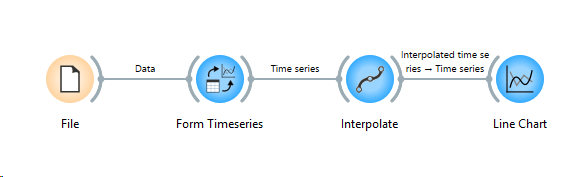
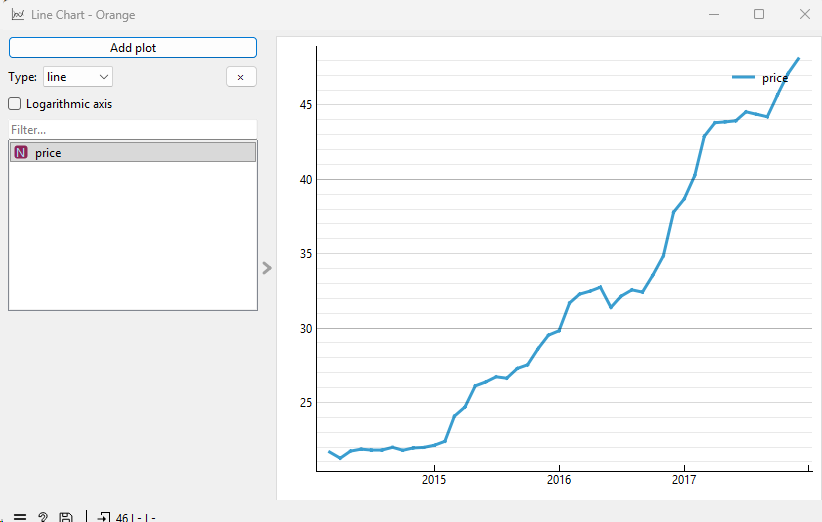

1. У середовищі Orange побудовано потік опрацювання часового ряду: `File` → `As Timeseries` → `Interpolate` → `Line Chart`.
2. Графік у віджеті `Line Chart` повністю збігається з лінійним графіком динаміки цін, побудованим у завданні 3.
*(напишіть тут)*

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [15]:
# Завдання 12. Автокореляція та диференціювання

**Висновок до завдання 12:**
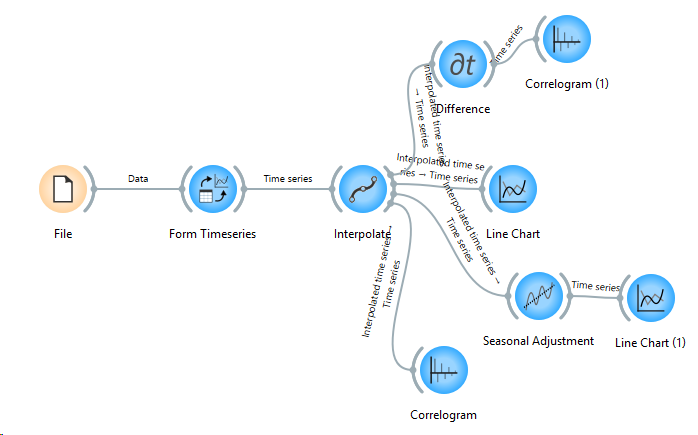
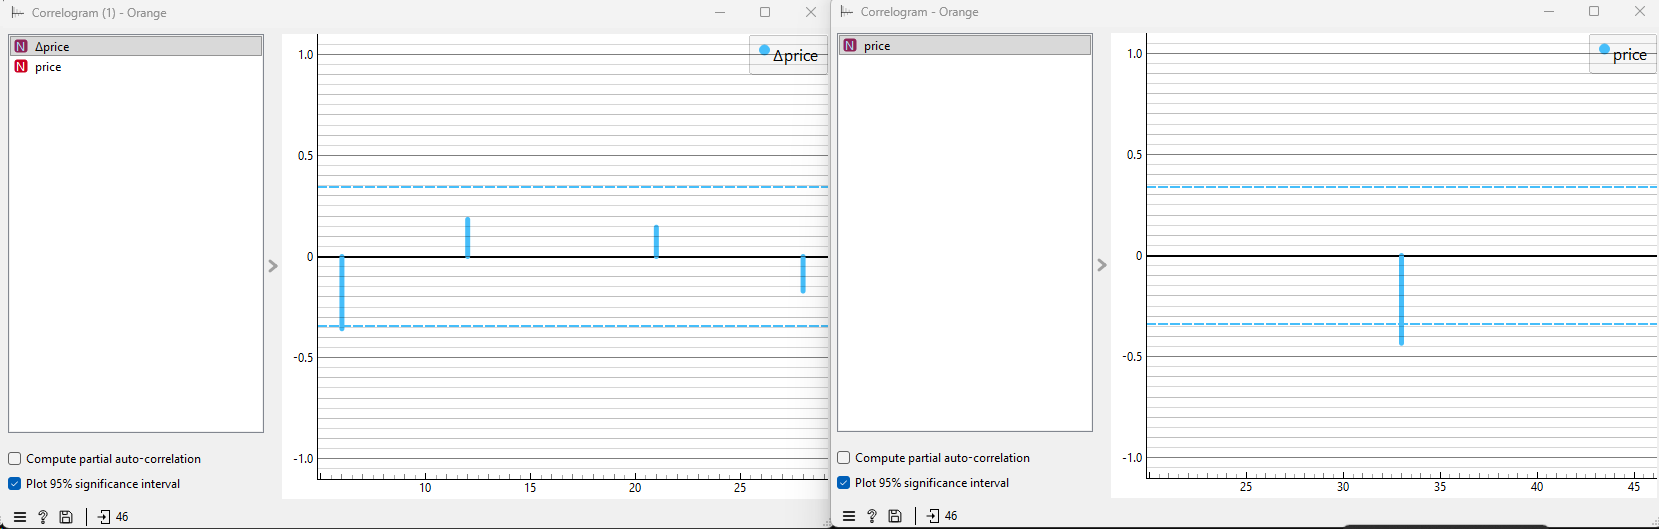
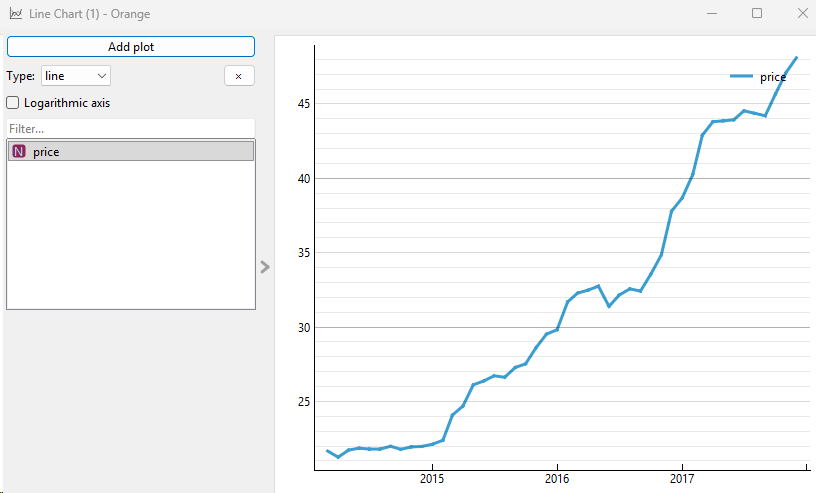

1. Корелограма (ACF), отримана у віджеті Correlogram, показує високі значення автокореляції на перших лагах, які спадають повільно й монотонно. Перші 9 лагів виходять за межі 95% довірчого інтервалу.   Висновок повністю узгоджується з аналізом у завданні 5: вихідний ряд є нестаціонарним та має сильний висхідний тренд.   Після застосування віджета Difference ($d=1$) автокореляція різко падає, і переважна більшість значень опиняється всередині меж, що підтверджує стаціонарність першої різниці.
2. Сезонне коригування та зіставлення з розкладанням ST:  Отриманий скоригований ряд зберігає форму домінуючого висхідного тренду і повністю відповідає результатам STL-розкладання із завдання 4. Оскільки сила сезонності помірна ($F_S \approx 0.53$), очищений ряд візуально дуже близький до вихідного, за винятком згладжених локальних хвиль. 
*(напишіть тут)*

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [16]:
# Завдання 13. Модель і оцінювання

**Висновок до завдання 13:**
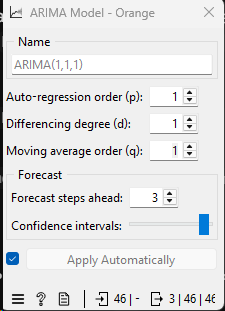
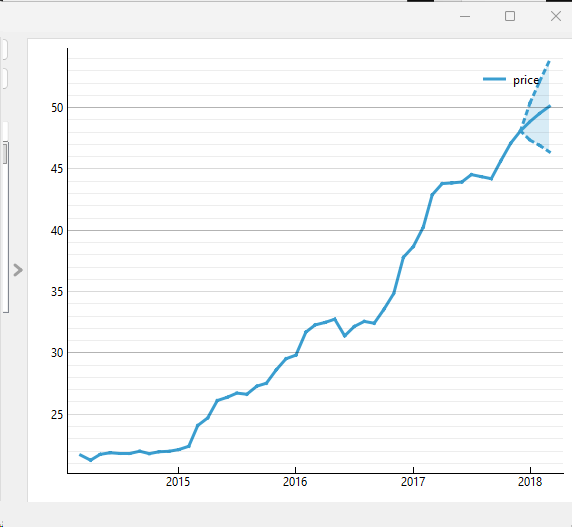

**Побудова та налаштування моделі ARIMA в Orange:**
   * У потік додано віджет `ARIMA Model`.
   * На основі аналізу стаціонарності та ACF/PACF із попередніх завдань задано параметри порядку моделі: $p = 1$, $d = 1$, $q = 1$.
   * Модель успішно ідентифікувала параметри авторегресії (коефіцієнт AR $\approx 0.86$) та ковзного середнього (коефіцієнт MA $\approx -0.47$), що повністю узгоджується з оцінками, отриманими у завданні 7.
*(напишіть тут)*

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [17]:
# Завдання 14. Чому числа не збігаються
from statsmodels.tsa.arima.model import ARIMA

actuals_list = []
predictions_list = []
prev_values_list = []


for i in range(n_folds):
    train = y[:init_train + i*step] 
    test = y[(init_train + i*step) : (init_train+(i+1)*step)]
    
    arima = ARIMA(train, order=(1, 1, 1))
    pred = arima.fit().forecast(steps=step)
    
    actuals_list.extend(test)
    predictions_list.extend(pred)
    
    prev = [train[-1]] + list(test[:-1])
    prev_values_list.extend(prev)

actuals = np.array(actuals_list)
predictions = np.array(predictions_list)
prev_values = np.array(prev_values_list)

calc_rmse = np.sqrt(np.mean((actuals - predictions) ** 2))
calc_mae = np.mean(np.abs(actuals - predictions))
calc_mape = np.mean(np.abs((actuals - predictions) / actuals)) 
calc_pocid = 100.0 * np.mean(((actuals - prev_values) * (predictions - prev_values)) > 0)

print(f"RMSE (Orange formula):  {calc_rmse:.3f}")
print(f"MAE (Orange formula):   {calc_mae:.3f}")
print(f"MAPE (Orange formula):  {calc_mape:.3f}") # Увага: це частка, а не відсотки
print(f"POCID (Orange formula): {calc_pocid:.1f}%")

RMSE (Orange formula):  2.174
MAE (Orange formula):   1.710
MAPE (Orange formula):  0.044
POCID (Orange formula): 57.1%


**Висновок до завдання 14:**
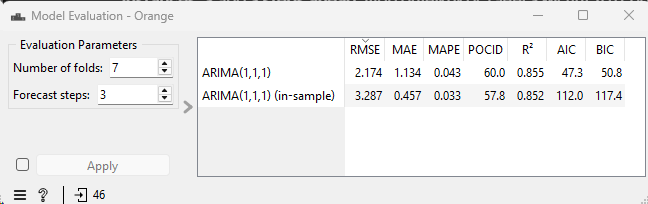
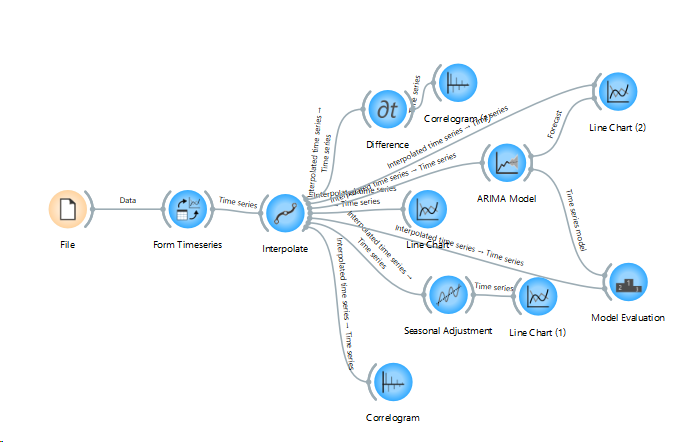
1. Яка метрика не відповідає своїй назві: Це MAPE. Зазвичай остання літера "P" означає "Percentage", тому значення має множитися на 100. Проте в Orange воно виводиться як частка від одиниці.

2. Яка метрика збіглася: RMSE та MAE збігаються, оскільки їх математичні формули ідентичні в обох середовищах.

3. Висновок: Перед тим як порівнювати цифри з різних програм, треба завжди перевіряти документацію або вихідний код і дивитись, як саме вони формулюють метрику.
*(напишіть тут)*

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [18]:
# Завдання 15. Матриця напрямку зміни
import pandas as pd
import numpy as np

actual_up = (actuals - prev_values) > 0
pred_up = (predictions - prev_values) > 0

df_dir = pd.DataFrame({
    'Actual': np.where(actual_up, 'Increased', 'Decreased/Unchanged'),
    'Predicted': np.where(pred_up, 'Increased', 'Decreased/Unchanged')
})

matrix = pd.crosstab(df_dir['Actual'], df_dir['Predicted'], 
                     rownames=['Actual (happened)'], 
                     colnames=['Model predicted'])

print("==== Direction of Change Matrix (Confusion Matrix) ====")
print(matrix)
print("\n")

correct_predictions = (df_dir['Actual'] == df_dir['Predicted']).sum()
total_predictions = len(df_dir)
pocid_calculated = (correct_predictions / total_predictions) * 100

print(f"Correct direction predictions: {correct_predictions} out of {total_predictions}")
print(f"Calculated ratio (POCID): {pocid_calculated:.1f}%")

==== Direction of Change Matrix (Confusion Matrix) ====
Model predicted      Decreased/Unchanged  Increased
Actual (happened)                                  
Decreased/Unchanged                    2          2
Increased                              7         10


Correct direction predictions: 12 out of 21
Calculated ratio (POCID): 57.1%


**Висновок до завдання 15:**
1. Заповнена матриця 2×2:
Фактично Впала/Без змін, Модель передбачила Впала/Без змін: 2
Фактично Впала/Без змін, Модель передбачила Зросла: 2
Фактично Зросла, Модель передбачила Впала/Без змін: 7
Фактично Зросла, Модель передбачила Зросла: 10

2. Перевірка:
Загалом модель зробила 21 прогноз на тестових відрізках, з яких напрямок було вгадано правильно у 12 випадках. Частка правильних передбачень становить 12 / 21 = 0.5714, або 57.1%. Цей розрахунок абсолютно збігається зі значенням метрики POCID, яке вивів Orange у попередньому завданні.

3. Корисність моделі та різниця з MAE/RMSE:
Модель із точністю вгадування напрямку 57.1% навряд чи корисна для ухвалення рішення «купувати зараз чи чекати». MAE та RMSE оцінюють абсолютну величину похибки у гривнях. Натомість POCID вимірює правильність бінарного рішення. Наприклад, якщо вчора ціна була 44.4, сьогодні впала 44., а модель передбачила 44.5 — похибка в гривнях дуже мала (MAE буде низьким), але напрямок передбачено неправильно, що призведе до помилкового фінансового рішення.
*(напишіть тут)*

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

У моєму ряді цін на сметану немає вираженої математичної сезонності. Я довів це за допомогою розкладання STL, де сила сезонності виявилася нижчою за порогове значення (близько 0.53). Найкращим методом прогнозування для цього ряду виявився простий базис «Дрейф». Він перевершив як звичайний наївний прогноз, так і складнішу модель ARIMA(1,1,1), оскільки ідеально підходить для рядів із сильним лінійним трендом. Також я знайшов точку зміни режиму в березні 2017 року, коли середній рівень ціни різко і назавжди зріс. Це пояснюється зовнішніми економічними чинниками, зокрема інфляцією в Україні, а не внутрішньою сезонністю товару. Під час порівняння середовищ я виявив, що однаково названі метрики дають різні числа через різні формули під капотом. Зрештою, через те, що мій ряд має лише 46 спостережень, я не зміг побудувати стабільну та надійну модель ARIMA. Такої кількості даних просто замало для навчання складних алгоритмів без ризику перенавчання

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini |
| Для яких саме завдань | 4, 5, 6, 7, 8 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | пояснення коду, текст |
| Що ви змінили у згенерованому результаті й чому | генерував в більшості  |
| Що з отриманого ви **перевірили самостійно** і яким способом | |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________